In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
import os, sys
ROOT = '/content/drive/MyDrive/DSP_Deconv'
for d in ['lib', 'data/raw', 'data/processed', 'results', 'figures', 'configs']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
if f'{ROOT}/lib' not in sys.path:
    sys.path.insert(0, f'{ROOT}/lib')
print(os.listdir(ROOT))

['lib', 'data', 'results', 'figures', 'configs', '03_experiments.ipynb', '02_proposed.ipynb', '04_real_data.ipynb', '00_setup_data.ipynb', '01_forward_baselines_new.ipynb', '01_forward_baselines.ipynb', '03_experiments_new.ipynb', '04_real_data_new.ipynb', '05_figures_new.ipynb', '02_proposed_new.ipynb']


In [ ]:
!pip -q install scikit-image tifffile pyyaml

import sys
import importlib

if "imp" not in sys.modules:
    sys.modules["imp"] = importlib

%load_ext autoreload
%autoreload 2

import numpy as np, scipy, skimage, matplotlib.pyplot as plt
print('numpy', np.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
numpy 2.1.3 | scipy 1.16.3 | skimage 0.25.2


In [ ]:
import yaml
CFG_PATH = f'{ROOT}/configs/params.yaml'
if not os.path.exists(CFG_PATH):
    cfg = dict(
        seeds=[0, 1, 2, 3, 4],
        psf_sigmas=[1.5, 2.5, 4.0],            
        gauss_noise=[0.005, 0.01, 0.02, 0.05], 
        poisson_peaks=[30, 100, 300],           
        crop=256,                               
        eps_band=1e-3,                          
    )
    yaml.safe_dump(cfg, open(CFG_PATH, 'w'))
cfg = yaml.safe_load(open(CFG_PATH))
cfg

{'crop': 256,
 'eps_band': 0.001,
 'gauss_noise': [0.005, 0.01, 0.02, 0.05],
 'poisson_peaks': [30, 100, 300],
 'psf_sigmas': [1.5, 2.5, 4.0],
 'seeds': [0, 1, 2, 3, 4]}

In [ ]:
%%writefile /content/drive/MyDrive/DSP_Deconv/lib/forward.py
import numpy as np
from numpy.fft import fft2, ifft2, fftfreq

def psf_size(sigma):
    return int(8 * sigma) | 1                   

def gaussian_psf(size, sigma):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    h = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return h / h.sum()                           

def airy_psf(size, radius):
    """Diffraction-limited PSF; radius = first dark ring in pixels."""
    from scipy.special import j1
    ax = np.arange(size) - size // 2
    r = np.hypot(*np.meshgrid(ax, ax)) * 3.8317 / radius
    r[r == 0] = 1e-12
    h = (2 * j1(r) / r) ** 2
    return h / h.sum()

def psf2otf(psf, shape):
    """Zero-pad the PSF to the image size and move its centre to pixel (0,0), so H has no phase ramp."""
    pad = np.zeros(shape)
    kh, kw = psf.shape
    pad[:kh, :kw] = psf
    pad = np.roll(pad, (-(kh // 2), -(kw // 2)), axis=(0, 1))
    return fft2(pad)

def blur(x, psf, boundary='periodic'):
    if boundary == 'periodic':                 
        return np.real(ifft2(fft2(x) * psf2otf(psf, x.shape)))
    from scipy.ndimage import convolve          
    return convolve(x, psf, mode='reflect')

def add_gaussian(y, sigma, rng):
    return y + sigma * rng.standard_normal(y.shape)

def add_poisson_gaussian(y, peak, read_sigma, rng):
    """peak = photon count at brightness 1.0; fewer photons = noisier."""
    return rng.poisson(np.clip(y, 0, None) * peak) / peak + read_sigma * rng.standard_normal(y.shape)

def freq_grid(shape):
    """Radial spatial frequency |w| of every FFT bin, in cycles/pixel (0 ... 0.707)."""
    wy = fftfreq(shape[0])[:, None]
    wx = fftfreq(shape[1])[None, :]
    return np.hypot(wx, wy)

def edge_phantom(n=256, low=0.2, high=0.8):
    """Vertical step edge: exact ground truth for edge width, overshoot and noise in flat areas."""
    x = np.full((n, n), low)
    x[:, n // 2:] = high
    return x

Overwriting /content/drive/MyDrive/DSP_Deconv/lib/forward.py


In [ ]:
%%writefile /content/drive/MyDrive/DSP_Deconv/lib/data.py
from pathlib import Path
import numpy as np, skimage.io as io
ROOT = Path('/content/drive/MyDrive/DSP_Deconv')

def _read(p):
    im = io.imread(p).astype(np.float64)
    return im.mean(-1) if im.ndim == 3 else im

def fmd_pair(subset, fov, frame=0):
    """Clean 50-frame average (gt) and one raw noisy frame. Change '*.png' if Cell 6 shows .tif files."""
    base = ROOT / 'data/raw/FMD' / subset
    gt = _read(sorted((base / 'gt' / str(fov)).glob('*.png'))[0])
    raw = _read(sorted((base / 'raw' / str(fov)).glob('*.png'))[frame])
    return gt, raw

def norm_pair(gt, *others):
    """Scale to 0-1 with the clean image's 0.5/99.5 percentiles; the same scale for every image of the set."""
    lo, hi = np.percentile(gt, [0.5, 99.5])
    f = lambda im: (im - lo) / (hi - lo)
    return (np.clip(f(gt), 0, 1),) + tuple(f(o) for o in others)

def center_crop(im, n):
    r, c = (im.shape[0] - n) // 2, (im.shape[1] - n) // 2
    return im[r:r + n, c:c + n]

def quadrants(im, n=256):
    """Four non-overlapping n x n crops: more test images from one field of view."""
    return [im[:n, :n], im[:n, n:2*n], im[n:2*n, :n], im[n:2*n, n:2*n]]

Overwriting /content/drive/MyDrive/DSP_Deconv/lib/data.py


In [ ]:
%%writefile /content/drive/MyDrive/DSP_Deconv/lib/metrics.py
import numpy as np
from numpy.fft import fft2
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

def psnr(x, xh):
    return peak_signal_noise_ratio(x, xh, data_range=1.0)

def ssim(x, xh):
    return structural_similarity(x, xh, data_range=1.0)

def lsd(x, xh):
    """Log-spectral distance in dB between true and restored spectra."""
    P = np.abs(fft2(x)) ** 2 + 1e-12
    Q = np.abs(fft2(xh)) ** 2 + 1e-12
    return np.sqrt(np.mean((10 * np.log10(P / Q)) ** 2))

def fwhm(lsf):
    """Full width at half maximum of a 1-D peak, with sub-pixel interpolation."""
    lsf = np.asarray(lsf, float); i = int(np.argmax(lsf)); half = lsf[i] / 2
    l = i
    while l > 0 and lsf[l] > half: l -= 1
    r = i
    while r < len(lsf) - 1 and lsf[r] > half: r += 1
    xl = l + (half - lsf[l]) / (lsf[l + 1] - lsf[l] + 1e-12)
    xr = r - (half - lsf[r]) / (lsf[r - 1] - lsf[r] + 1e-12)
    return xr - xl

def edge_metrics(xh, low=0.2, high=0.8, margin=40):
    """For edge_phantom outputs: edge width, MTF50, overshoot %, noise std in the flat dark half."""
    n = xh.shape[1]
    esf = xh[:, n // 2 - margin:n // 2 + margin].mean(0)    
    lsf = np.diff(esf)                                      
    c = int(np.argmax(lsf))
    win = lsf[max(c - 16, 0):c + 17]                        
    M = np.abs(np.fft.rfft(win, 256)); M /= M[0]
    f = np.fft.rfftfreq(256)
    below = np.nonzero(M < 0.5)[0]
    return dict(
        fwhm_px=fwhm(lsf),
        mtf50=f[below[0]] if below.size else 0.5,
        overshoot_pct=100 * max(0.0, esf.max() - high) / (high - low),
        flat_std=xh[:, margin:n // 2 - margin].std(),
    )

def noise_gain(xh_noisy, xh_clean, y_noisy, y_clean):
    """Noise amplification = output noise std / input noise std. Works on real data when a clean reference exists."""
    return (xh_noisy - xh_clean).std() / (y_noisy - y_clean).std()

Overwriting /content/drive/MyDrive/DSP_Deconv/lib/metrics.py


In [ ]:
%%writefile /content/drive/MyDrive/DSP_Deconv/lib/baselines.py
import numpy as np
from numpy.fft import fft2, ifft2
from forward import psf2otf
from skimage.restoration import richardson_lucy, unsupervised_wiener

def _apply(y, H, lam):
    """X_hat = conj(H) Y / (|H|^2 + lambda(w)); lam may be a number or a per-frequency array."""
    return np.real(ifft2(np.conj(H) * fft2(y) / (np.abs(H) ** 2 + lam)))

def inverse(y, psf, eps=1e-30):                 
    return _apply(y, psf2otf(psf, y.shape), eps)

def wiener_const(y, psf, nsr):                  
    return _apply(y, psf2otf(psf, y.shape), nsr)

def wiener_oracle(y, psf, x_true, sigma):
    """Upper bound: uses the TRUE signal spectrum. Only possible in simulation."""
    Sx = np.abs(fft2(x_true)) ** 2 / y.size      
    return _apply(y, psf2otf(psf, y.shape), sigma ** 2 / (Sx + 1e-12))

def laplacian_otf(shape):
    L = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], float)
    return psf2otf(L, shape)

def tikhonov(y, psf, lam):
    return _apply(y, psf2otf(psf, y.shape), lam * np.abs(laplacian_otf(y.shape)) ** 2)

def gcv_lambda(y, psf, lams=np.logspace(-6, 0, 61)):
    """Generalized cross-validation: picks lambda from y alone (no ground truth)."""
    H2 = np.abs(psf2otf(psf, y.shape)) ** 2
    L2 = np.abs(laplacian_otf(y.shape)) ** 2
    Y2 = np.abs(fft2(y)) ** 2
    scores = []
    for lam in lams:
        F = lam * L2 / (H2 + lam * L2)           
        scores.append(np.sum(F ** 2 * Y2) / np.sum(F) ** 2)
    return lams[int(np.argmin(scores))], np.array(scores)

def tikhonov_gcv(y, psf):
    return tikhonov(y, psf, gcv_lambda(y, psf)[0])

def rl(y, psf, n_iter=30):
    return richardson_lucy(np.clip(y, 1e-6, None), psf, num_iter=n_iter, clip=False)

def unsup_wiener(y, psf):
    return unsupervised_wiener(y, psf, clip=False)[0]

def padded(method, y, psf, pad=32, **kw):
    """Mirror-pad before FFT deconvolution, crop after: removes border ringing (used in S7)."""
    yp = np.pad(y, pad, mode='reflect')
    return method(yp, psf, **kw)[pad:-pad, pad:-pad]

Overwriting /content/drive/MyDrive/DSP_Deconv/lib/baselines.py


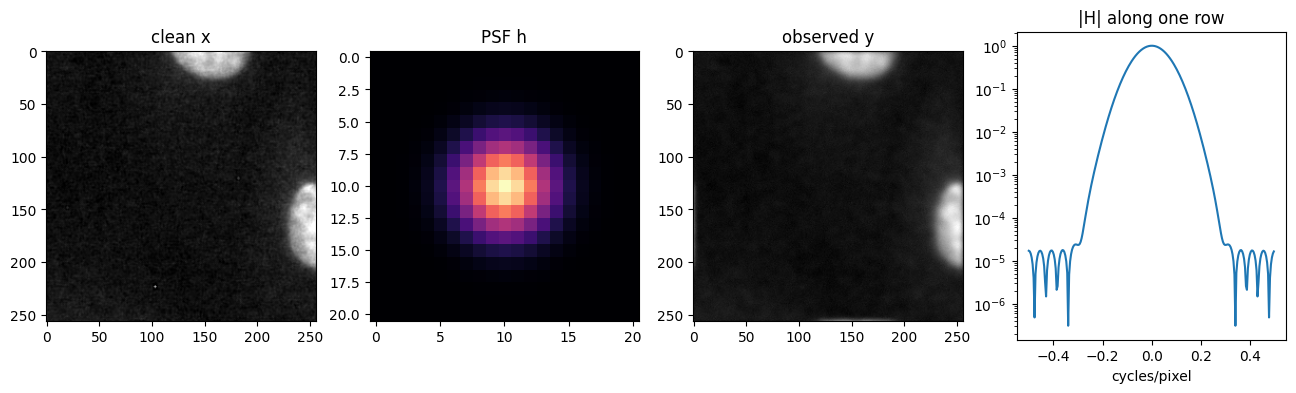

In [ ]:
from forward import *; from data import *
gt, raw = fmd_pair('WideField_BPAE_B', 1)
x = center_crop(norm_pair(gt)[0], cfg['crop'])
psf = gaussian_psf(psf_size(2.5), 2.5)
y = add_gaussian(blur(x, psf), 0.01, np.random.default_rng(0))
H = np.fft.fftshift(np.abs(psf2otf(psf, x.shape)))
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(x, cmap='gray'); ax[0].set_title('clean x')
ax[1].imshow(psf, cmap='magma'); ax[1].set_title('PSF h')
ax[2].imshow(y, cmap='gray'); ax[2].set_title('observed y')
ax[3].semilogy(np.fft.fftshift(np.fft.fftfreq(256)), H[128]); ax[3].set_title('|H| along one row'); ax[3].set_xlabel('cycles/pixel')
plt.show()

In [ ]:
from skimage import data as skd
from baselines import inverse
from forward import gaussian_psf, psf_size, blur, add_gaussian
import numpy as np

x = skd.camera()[:256, :256] / 255.0      
psf = gaussian_psf(psf_size(1.5), 1.5)
y0 = blur(x, psf)                                         
y1 = add_gaussian(y0, 0.001, np.random.default_rng(0))     
print('noiseless max error :', np.abs(inverse(y0, psf) - x).max())
print('tiny-noise max error:', np.abs(inverse(y1, psf) - x).max())

noiseless max error : 2.8326079704044105e-08
tiny-noise max error: 142091.1585310015


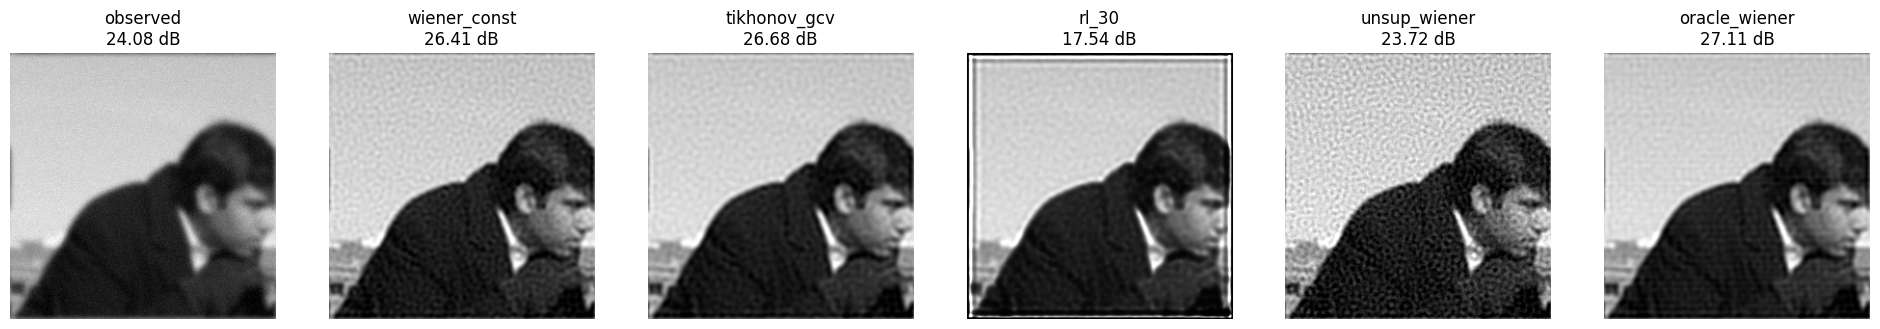

In [ ]:
from metrics import psnr
from baselines import wiener_const, tikhonov_gcv, rl, unsup_wiener, wiener_oracle
psf = gaussian_psf(psf_size(2.5), 2.5); sigma = 0.02
y = add_gaussian(blur(x, psf), sigma, np.random.default_rng(0))
outs = {
    'observed':      y,
    'wiener_const':  wiener_const(y, psf, 1e-2),
    'tikhonov_gcv':  tikhonov_gcv(y, psf),
    'rl_30':         rl(y, psf, 30),
    'unsup_wiener':  unsup_wiener(y, psf),
    'oracle_wiener': wiener_oracle(y, psf, x, sigma),
}
fig, ax = plt.subplots(1, len(outs), figsize=(4 * len(outs), 4))
for a, (k, v) in zip(ax, outs.items()):
    a.imshow(np.clip(v, 0, 1), cmap='gray'); a.set_title(f'{k}\n{psnr(x, np.clip(v, 0, 1)):.2f} dB'); a.axis('off')

In [ ]:
import yaml, numpy as np
from forward import *; from data import *; from baselines import *; from metrics import psnr

dev = []
for fov in [1, 2, 3]:                                   
    gt, _ = fmd_pair('WideField_BPAE_B', fov)
    dev.append(center_crop(norm_pair(gt)[0], cfg['crop']))

nsrs  = np.logspace(-4, 0, 17)
iters = [1, 2, 3, 4, 5, 7, 10, 20, 30, 50]
nsr_s = {n: [] for n in nsrs}
rl_s  = {k: [] for k in iters}

for xd in dev:
    for s_psf in cfg['psf_sigmas']:
        psf = gaussian_psf(psf_size(s_psf), s_psf)
        for s_n in cfg['gauss_noise']:
            y = add_gaussian(blur(xd, psf), s_n, np.random.default_rng(0))
            for n in nsrs:
                nsr_s[n].append(psnr(xd, np.clip(wiener_const(y, psf, n), 0, 1)))
            for k in iters:
                rl_s[k].append(psnr(xd, np.clip(rl(y, psf, k), 0, 1)))

mean_nsr = {n: np.mean(v) for n, v in nsr_s.items()}
mean_rl  = {k: np.mean(v) for k, v in rl_s.items()}
best_nsr  = float(max(mean_nsr, key=mean_nsr.get))
best_iter = int(max(mean_rl, key=mean_rl.get))
print('mean dev PSNR per RL iteration count:', {k: round(v, 2) for k, v in mean_rl.items()})
print('best nsr:', best_nsr, '| best rl_iter:', best_iter)
for name, best, grid in [('nsr', best_nsr, list(nsrs)), ('rl_iter', best_iter, iters)]:
    if best in (grid[0], grid[-1]):
        print(f'WARNING: best {name} = {best} is at the edge of its grid; widen the grid and re-run')

with open(f'{ROOT}/configs/tuned.yaml', 'w') as f:
    yaml.safe_dump(dict(nsr=best_nsr, rl_iter=best_iter), f)
print(open(f'{ROOT}/configs/tuned.yaml').read())

mean dev PSNR per RL iteration count: {1: np.float64(30.32), 2: np.float64(29.71), 3: np.float64(28.68), 4: np.float64(27.84), 5: np.float64(27.18), 7: np.float64(26.2), 10: np.float64(25.26), 20: np.float64(23.71), 30: np.float64(22.91), 50: np.float64(21.9)}
best nsr: 0.03162277660168379 | best rl_iter: 1
nsr: 0.03162277660168379
rl_iter: 1



In [ ]:
from skimage.restoration import unsupervised_wiener
for s_psf, s_n in [(1.5, 0.01), (4.0, 0.05)]:
    psf = gaussian_psf(psf_size(s_psf), s_psf)
    y = add_gaussian(blur(dev[0], psf), s_n, np.random.default_rng(0))
    xh, chains = unsupervised_wiener(y, psf, clip=False, rng=0)
    sigma_est = 1 / np.sqrt(np.mean(chains['noise']))     
    print(f'PSF {s_psf} px, true sigma {s_n}: sampler sigma {sigma_est:.4f} | PSNR {psnr(dev[0], np.clip(xh, 0, 1)):.2f} dB')

PSF 1.5 px, true sigma 0.01: sampler sigma 0.0106 | PSNR 31.42 dB
PSF 4.0 px, true sigma 0.05: sampler sigma 0.0511 | PSNR 19.86 dB
